<a href="https://colab.research.google.com/github/mikiTakii/ARQ/blob/main/robustness_colabV2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Formalna verifikacija robusnosti — PneumoniaMNIST

Runtime → Change runtime type → **T4 GPU**. Pokreni ćelije redom. Modeli i rezultati se čuvaju na Google Drive (`OUT`), pa prekid sesije ne briše posao.

In [ ]:
!pip -q install medmnist pyyaml graphviz appdirs
!pip -q install --no-deps --ignore-requires-python git+https://github.com/Verified-Intelligence/auto_LiRPA.git
import torch; print(torch.__version__, 'GPU:', torch.cuda.is_available())

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
2.14.1+cu130 GPU: True


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/robust'
import os; os.makedirs(OUT, exist_ok=True); print(OUT)

Mounted at /content/drive
/content/drive/MyDrive/robust


## Kod (core.py, run.py, spec.yaml)

In [ ]:
%%writefile core.py
"""Jezgro: podaci, model, napadi i formalna verifikacija.

Dve vrste specifikacije:
  * L-inf: ||x' - x||_inf <= eps  (adversarial primeri, Clan 15(5))
  * Akvizicija (parametri snimanja): x' = c * (x - mean(x)) + mean(x) + b,
    c u [c_lo, c_hi] (kontrast), b u [b_lo, b_hi] (osvetljenje).
    Ulaz u verifikator su samo 2 parametra, pa CROWN ostaje precizan.
"""
import math
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

CLASSES = ["normal", "pneumonia"]


# ----------------------------------------------------------------------------
# Podaci
# ----------------------------------------------------------------------------
def load_data(synthetic=False, n_synth=2000, seed=0):
    """Vraca dict split -> (X float32 [N,1,28,28] u [0,1], y int64 [N])."""
    if synthetic:
        g = np.random.default_rng(seed)
        out = {}
        for split, n in [("train", n_synth), ("val", n_synth // 5), ("test", n_synth // 4)]:
            y = g.integers(0, 2, n)
            X = g.normal(0.45, 0.08, (n, 1, 28, 28))
            yy, xx = np.mgrid[0:28, 0:28]
            blob = np.exp(-((yy - 14) ** 2 + (xx - 10) ** 2) / 30.0)
            X += (y[:, None, None, None] * 0.35) * blob  # "zamucenje" za pneumoniju
            out[split] = (np.clip(X, 0, 1).astype(np.float32), y.astype(np.int64))
        return out
    import medmnist  # pip install medmnist (skida sa zenodo.org)
    out = {}
    for split in ["train", "val", "test"]:
        ds = medmnist.PneumoniaMNIST(split=split, download=True, size=28)
        X = (ds.imgs.astype(np.float32) / 255.0)[:, None, :, :]
        y = ds.labels.reshape(-1).astype(np.int64)
        out[split] = (X, y)
    return out


def loader(X, y, batch=128, shuffle=True):
    ds = torch.utils.data.TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    return torch.utils.data.DataLoader(ds, batch_size=batch, shuffle=shuffle)


# ----------------------------------------------------------------------------
# Model (bez BatchNorm-a, da bi verifikacija bila jednostavna i precizna)
# ----------------------------------------------------------------------------
def make_model():
    return nn.Sequential(
        nn.Conv2d(1, 16, 4, stride=2, padding=1), nn.ReLU(),
        nn.Conv2d(16, 32, 4, stride=2, padding=1), nn.ReLU(),
        nn.Flatten(),
        nn.Linear(32 * 7 * 7, 100), nn.ReLU(),
        nn.Linear(100, 2),
    )


def acquire(x, c, b):
    """Model akvizicije: kontrast c oko srednje vrednosti slike + osvetljenje b."""
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    return c.view(-1, 1, 1, 1) * (x - m) + m + b.view(-1, 1, 1, 1)


@torch.no_grad()
def accuracy(model, X, y, device, batch=512):
    model.eval()
    correct, preds = 0, []
    for i in range(0, len(X), batch):
        xb = torch.from_numpy(X[i:i + batch]).to(device)
        p = model(xb).argmax(1).cpu()
        preds.append(p)
    preds = torch.cat(preds).numpy()
    return float((preds == y).mean()), preds


# ----------------------------------------------------------------------------
# Napadi
# ----------------------------------------------------------------------------
def pgd_linf(model, x, y, eps, steps=20, alpha=None, restarts=1):
    """PGD u L-inf lopti, slika ostaje u [0,1]. Vraca adversarial slike."""
    if eps <= 0:
        return x.clone()
    alpha = alpha or 2.5 * eps / steps
    model.eval()
    best = x.clone()
    fooled = torch.zeros(len(x), dtype=torch.bool, device=x.device)
    for _ in range(restarts):
        delta = (torch.rand_like(x) * 2 - 1) * eps
        for _ in range(steps):
            delta.requires_grad_(True)
            loss = F.cross_entropy(model((x + delta).clamp(0, 1)), y)
            g, = torch.autograd.grad(loss, delta)
            delta = (delta.detach() + alpha * g.sign()).clamp(-eps, eps)
        adv = (x + delta).clamp(0, 1).detach()
        with torch.no_grad():
            now = model(adv).argmax(1) != y
        new = now & ~fooled
        best[new] = adv[new]
        fooled |= now
    return best


@torch.no_grad()
def acquisition_attack(model, x, y, c_rng, b_rng, grid=21):
    """Gusta pretraga po (kontrast, osvetljenje). Vraca (fooled, c*, b*, pred*)."""
    model.eval()
    cs = torch.linspace(*c_rng, grid, device=x.device)
    bs = torch.linspace(*b_rng, grid, device=x.device)
    C, B = torch.meshgrid(cs, bs, indexing="ij")
    C, B = C.reshape(-1), B.reshape(-1)
    n = len(x)
    fooled = torch.zeros(n, dtype=torch.bool, device=x.device)
    cx = torch.full((n,), float("nan"), device=x.device)
    bx = cx.clone()
    px = torch.full((n,), -1, dtype=torch.long, device=x.device)
    for i in range(n):
        xi = x[i:i + 1].expand(len(C), -1, -1, -1)
        pred = model(acquire(xi, C, B)).argmax(1)
        bad = (pred != y[i]).nonzero().flatten()
        if len(bad):
            # najblizi kontraprimer identitetu (c=1, b=0)
            d = (C[bad] - 1).abs() + B[bad].abs()
            j = bad[d.argmin()]
            fooled[i], cx[i], bx[i], px[i] = True, C[j], B[j], pred[j]
    return fooled, cx, bx, px


# ----------------------------------------------------------------------------
# Formalna verifikacija
# ----------------------------------------------------------------------------
def _spec_matrix(y, k=2):
    """C tako da je C @ logits = logit_y - logit_j za svako j != y."""
    n = len(y)
    E = F.one_hot(y, k).float()                                   # (n,k)
    full = E[:, None, :] - torch.eye(k, device=y.device)[None]      # (n,k,k), red j: e_y - e_j
    keep = E == 0                                                   # izbaci red j == y
    return full[keep].view(n, k - 1, k)


def _ibp(net, lo, hi):
    """Interval bound propagation (rezervna opcija bez auto_LiRPA)."""
    for layer in net:
        if isinstance(layer, (nn.Conv2d, nn.Linear)):
            mid, rad = (hi + lo) / 2, (hi - lo) / 2
            W = layer.weight
            if isinstance(layer, nn.Conv2d):
                f = lambda t, w, b=None: F.conv2d(t, w, b, layer.stride, layer.padding)
            else:
                f = lambda t, w, b=None: F.linear(t, w, b)
            mid, rad = f(mid, W, layer.bias), f(rad, W.abs())
            lo, hi = mid - rad, mid + rad
        elif isinstance(layer, nn.ReLU):
            lo, hi = lo.clamp(min=0), hi.clamp(min=0)
        elif isinstance(layer, nn.Flatten):
            lo, hi = lo.flatten(1), hi.flatten(1)
        else:
            raise ValueError(f"IBP ne podrzava sloj {layer}")
    return lo, hi


def _has_lirpa():
    try:
        import auto_LiRPA  # noqa: F401
        return True
    except Exception:
        return False


class Verifier:
    """Formalna verifikacija. method: 'crown' (auto_LiRPA) ili 'ibp' (rezerva)."""

    def __init__(self, net, device, method="crown"):
        self.net = net.eval()
        self.device = device
        self.method = method if (method != "crown" or _has_lirpa()) else "ibp"
        self._lin = None

    # -- L-inf --------------------------------------------------------------
    @torch.no_grad()
    def certify_linf(self, x, y, eps, batch=256):
        """True ako je dokazano da nijedna slika u L-inf lopti ne menja klasu."""
        out = []
        for i in range(0, len(x), batch):
            xb, yb = x[i:i + batch], y[i:i + batch]
            lo, hi = (xb - eps).clamp(0, 1), (xb + eps).clamp(0, 1)
            out.append(self._margin_lb_img(xb, yb, lo, hi) > 0)
        return torch.cat(out)

    def _margin_lb_img(self, x, y, lo, hi):
        C = _spec_matrix(y)
        if self.method == "ibp":
            l, u = _ibp(self.net, lo, hi)
            return torch.einsum("nkc,nc->nk", C.clamp(min=0), l).add(
                torch.einsum("nkc,nc->nk", C.clamp(max=0), u)).min(1).values
        from auto_LiRPA import BoundedModule, BoundedTensor, PerturbationLpNorm
        if self._lin is None:
            self._lin = BoundedModule(self.net, torch.zeros(1, 1, 28, 28, device=self.device),
                                      device=self.device, verbose=0)
        ptb = PerturbationLpNorm(norm=float("inf"), x_L=lo, x_U=hi)
        lb, _ = self._lin.compute_bounds(x=(BoundedTensor(x, ptb),), C=C, method="CROWN", bound_upper=False)
        return lb.min(1).values

    # -- Akvizicija (kontrast, osvetljenje) ----------------------------------
    @torch.no_grad()
    def _margin_lb_acq(self, x0, y, pl, pu):
        """Donja granica margine za kutiju parametara [pl, pu] (N x 2)."""
        C = _spec_matrix(y)
        if self.method == "ibp":
            lo, hi = _acq_interval(x0, pl, pu)
            l, u = _ibp(self.net, lo, hi)
            return torch.einsum("nkc,nc->nk", C.clamp(min=0), l).add(
                torch.einsum("nkc,nc->nk", C.clamp(max=0), u)).min(1).values
        # sopstvena forward linearna relaksacija nad 2 parametra (ne treba auto_LiRPA)
        return forward_linear_margin(self.net, x0, y, pl, pu)

    @torch.no_grad()
    def certify_acquisition(self, x, y, c_rng, b_rng, max_depth=6, chunk=2048):
        """Branch-and-bound po prostoru parametara snimanja.

        Za svaku sliku vraca status: 'certified' (dokaz za ceo opseg),
        'falsified' (nadjen kontraprimer) ili 'unknown' (dokaz nije zavrsen).
        """
        n = len(x)
        status = ["certified"] * n
        boxes = [(i, c_rng[0], c_rng[1], b_rng[0], b_rng[1], 0) for i in range(n)]
        while boxes:
            nxt = []
            for s in range(0, len(boxes), chunk):
                part = [bx for bx in boxes[s:s + chunk] if status[bx[0]] == "certified"]
                if not part:
                    continue
                idx = torch.tensor([bx[0] for bx in part], device=self.device)
                pl = torch.tensor([[bx[1], bx[3]] for bx in part], device=self.device)
                pu = torch.tensor([[bx[2], bx[4]] for bx in part], device=self.device)
                ok = self._margin_lb_acq(x[idx], y[idx], pl, pu) > 0
                for bx, good in zip(part, ok.tolist()):
                    if good:
                        continue
                    i, cl, cu, bl, bu, d = bx
                    cm, bm = (cl + cu) / 2, (bl + bu) / 2
                    # da li je centar kutije pravi kontraprimer?
                    xc = acquire(x[i:i + 1], torch.tensor([cm], device=self.device),
                                 torch.tensor([bm], device=self.device))
                    if self.net(xc).argmax(1).item() != int(y[i]):
                        status[i] = "falsified"
                    elif d >= max_depth:
                        status[i] = "unknown"
                    else:
                        nxt += [(i, cl, cm, bl, bm, d + 1), (i, cm, cu, bl, bm, d + 1),
                                (i, cl, cm, bm, bu, d + 1), (i, cm, cu, bm, bu, d + 1)]
            boxes = nxt
        return status


def _concretize(Lc, pl, pu, lower=True):
    """min (ili max) linearne forme Lc (N, P+1, F) po kutiji p u [pl, pu]."""
    coef, const = Lc[:, :-1], Lc[:, -1]
    lo, hi = pl.unsqueeze(-1), pu.unsqueeze(-1)
    if lower:
        return const + torch.where(coef > 0, coef * lo, coef * hi).sum(1)
    return const + torch.where(coef > 0, coef * hi, coef * lo).sum(1)


def forward_linear_margin(net, x0, y, pl, pu):
    """Sopstveni verifikator za parametre snimanja (forward linearna relaksacija).

    Svaki neuron se drzi kao donja i gornja linearna funkcija parametara p=(c,b):
    tensor oblika (N, 3, ...) gde su [:,0] i [:,1] koeficijenti uz c i b, a [:,2] konstanta.
    Ulaz je tacno afin u p, pa relaksacija uvodi gresku samo na nestabilnim ReLU-ovima.
    Vraca donju granicu min_j (logit_y - logit_j) za svaku kutiju.
    """
    m = x0.mean(dim=(1, 2, 3), keepdim=True)
    d = x0 - m
    form = torch.stack([d, torch.ones_like(x0), m.expand_as(x0)], 1)  # (N,3,1,28,28)
    L, U = form, form.clone()
    N = len(x0)
    for layer in net:
        if isinstance(layer, (nn.Conv2d, nn.Linear)):
            Wp, Wn = layer.weight.clamp(min=0), layer.weight.clamp(max=0)
            sh = L.shape
            l2, u2 = L.reshape(N * 3, *sh[2:]), U.reshape(N * 3, *sh[2:])
            if isinstance(layer, nn.Conv2d):
                op = lambda t, w: F.conv2d(t, w, None, layer.stride, layer.padding)
            else:
                op = lambda t, w: F.linear(t, w)
            nl = op(l2, Wp) + op(u2, Wn)
            nu = op(u2, Wp) + op(l2, Wn)
            nl = nl.reshape(N, 3, *nl.shape[1:])
            nu = nu.reshape(N, 3, *nu.shape[1:])
            if layer.bias is not None:
                bshape = (1,) + tuple(layer.bias.shape) + (1,) * (nl.dim() - 3)
                nl[:, 2] += layer.bias.view(bshape[1:])
                nu[:, 2] += layer.bias.view(bshape[1:])
            L, U = nl, nu
        elif isinstance(layer, nn.Flatten):
            L, U = L.flatten(2), U.flatten(2)
        elif isinstance(layer, nn.ReLU):
            fl, fu = L.flatten(2), U.flatten(2)
            l = _concretize(fl, pl, pu, lower=True)
            u = _concretize(fu, pl, pu, lower=False)
            active, dead = l >= 0, u <= 0
            unstable = ~active & ~dead
            # gornja: u/(u-l) * (z - l) ; donja: alpha * z, alpha in {0,1}
            s = torch.where(unstable, u / (u - l).clamp(min=1e-12), active.float())
            shift = torch.where(unstable, -s * l, torch.zeros_like(l))
            alpha = torch.where(unstable, (u > -l).float(), active.float())
            nu = fu * s.unsqueeze(1)
            nu[:, 2] += shift
            nl = fl * alpha.unsqueeze(1)
            L, U = nl.reshape(L.shape), nu.reshape(U.shape)
        else:
            raise ValueError(f"Nepodrzan sloj {layer}")
    # margina: logit_y - logit_j
    Cm = _spec_matrix(y, k=L.shape[-1])                       # (N, K-1, K)
    Cp, Cn = Cm.clamp(min=0), Cm.clamp(max=0)
    marg = torch.einsum("nkc,nqc->nqk", Cp, L) + torch.einsum("nkc,nqc->nqk", Cn, U)  # (N,3,K-1)
    return _concretize(marg, pl, pu, lower=True).min(1).values


def _acq_interval(x0, pl, pu):
    """Interval slike za kutiju parametara (koristi ga samo IBP rezerva)."""
    m = x0.mean(dim=(1, 2, 3), keepdim=True)
    d = x0 - m
    cl, cu = pl[:, 0].view(-1, 1, 1, 1), pu[:, 0].view(-1, 1, 1, 1)
    bl, bu = pl[:, 1].view(-1, 1, 1, 1), pu[:, 1].view(-1, 1, 1, 1)
    lo = torch.minimum(cl * d, cu * d) + m + bl
    hi = torch.maximum(cl * d, cu * d) + m + bu
    return lo, hi


# ----------------------------------------------------------------------------
# Trening
# ----------------------------------------------------------------------------
def train(model, X, y, device, epochs=10, lr=1e-3, harden=None, log=print):
    """Standardni trening, ili ojacavanje ako je zadat harden dict:
    {'eps': 2/255, 'contrast': [0.8, 1.2], 'brightness': [-0.1, 0.1], 'pgd_steps': 7,
     'cert_weight': 1.0, 'cert_contrast': [0.7, 1.3], 'cert_brightness': [-0.15, 0.15], 'ramp_epochs': 4}
    cert_weight > 0 ukljucuje trening ka sertifikatu: donja granica margine iz verifikatora
    (forward_linear_margin) ulazi u funkciju greske, pa model uci da bude dokazivo robustan.
    """
    model.to(device).train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    # tezine klasa: PneumoniaMNIST je neuravnotezen (~74% pneumonija)
    w = torch.tensor(np.bincount(y, minlength=2), dtype=torch.float32)
    w = (w.sum() / (2 * w)).to(device)
    cw = (harden or {}).get("cert_weight", 0)
    for ep in range(epochs):
        t0, tot, n, ncert = time.time(), 0.0, 0, 0
        k = min(1.0, (ep + 1) / max(1, (harden or {}).get("ramp_epochs", 1)))  # rast kutije
        for xb, yb in loader(X, y):
            xb, yb = xb.to(device), yb.to(device)
            x_clean = xb
            if harden:
                c = torch.empty(len(xb), device=device).uniform_(*harden["contrast"])
                b = torch.empty(len(xb), device=device).uniform_(*harden["brightness"])
                xb = acquire(xb, c, b)
                if harden.get("eps", 0) > 0:
                    model.eval()
                    xb = pgd_linf(model, xb.clamp(0, 1), yb, harden["eps"], steps=harden.get("pgd_steps", 7))
                    model.train()
            loss = F.cross_entropy(model(xb), yb, weight=w)
            if cw > 0:
                cl, cu = harden["cert_contrast"]
                bl, bu = harden["cert_brightness"]
                pl = torch.tensor([[1 - k * (1 - cl), k * bl]], device=device).expand(len(yb), 2)
                pu = torch.tensor([[1 + k * (cu - 1), k * bu]], device=device).expand(len(yb), 2)
                lb = forward_linear_margin(model, x_clean, yb, pl, pu)
                loss = loss + cw * (w[yb] * F.relu(1.0 - lb)).mean()
                ncert += int((lb > 0).sum())
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * len(xb)
            n += len(xb)
        extra = f"  dokazivo na treningu={ncert / n:.3f} (kutija {k:.0%})" if cw > 0 else ""
        log(f"  epoha {ep + 1}/{epochs}  loss={tot / n:.4f}{extra}  ({time.time() - t0:.1f}s)")
    return model.eval()


Overwriting core.py


In [ ]:
%%writefile run.py
"""CLI: trening, napadi i verifikacija -> results.json.

Primeri:
  python run.py train  --spec spec.yaml --out models/baseline.pt
  python run.py train  --spec spec.yaml --harden --init models/baseline.pt --out models/hardened.pt
  python run.py verify --spec spec.yaml --model models/baseline.pt --out results/baseline
Dodaj --synthetic za brzi test bez skidanja podataka.
"""
import argparse
import json
import os
import time

import numpy as np
import torch
import yaml

import core


def get_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def cmd_train(args, spec):
    dev = get_device()
    data = core.load_data(synthetic=args.synthetic)
    X, y = data["train"]
    model = core.make_model().to(dev)
    if args.init:
        model.load_state_dict(torch.load(args.init, map_location=dev))
    tr = spec["train"]
    if args.harden:
        h = spec["harden"]
        print(f"Ojacavanje: eps={h['eps']:.4f}, kontrast={h['contrast']}, osvetljenje={h['brightness']}")
        core.train(model, X, y, dev, epochs=h["epochs"], lr=h["lr"], harden=h)
    else:
        print("Standardni trening")
        core.train(model, X, y, dev, epochs=tr["epochs"], lr=tr["lr"])
    acc, _ = core.accuracy(model, *data["test"], dev)
    print(f"Tacnost na testu: {acc:.4f}")
    os.makedirs(os.path.dirname(args.out) or ".", exist_ok=True)
    torch.save(model.state_dict(), args.out)
    print(f"Sacuvano: {args.out}")


def save_png(path, img, title):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(2.4, 2.6), dpi=110)
    ax.imshow(img.squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=8)
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(path)
    plt.close(fig)


def cmd_verify(args, spec):
    dev = get_device()
    t_start = time.time()
    data = core.load_data(synthetic=args.synthetic)
    Xt, yt = data["test"]
    model = core.make_model().to(dev)
    model.load_state_dict(torch.load(args.model, map_location=dev))
    model.eval()
    clean_acc, preds = core.accuracy(model, Xt, yt, dev)

    vs = spec["verify"]
    n = min(vs["n_samples"], len(Xt))
    g = np.random.default_rng(vs.get("seed", 0))
    idx = np.sort(g.choice(len(Xt), n, replace=False))
    x = torch.from_numpy(Xt[idx]).to(dev)
    y = torch.from_numpy(yt[idx]).to(dev)
    correct = torch.from_numpy(preds[idx] == yt[idx]).to(dev)

    ver = core.Verifier(model, dev, method=vs.get("method", "crown"))
    print(f"Verifikator: {ver.method}, uzorak: {n} slika, cista tacnost (ceo test): {clean_acc:.4f}")
    os.makedirs(args.out, exist_ok=True)
    img_dir = os.path.join(args.out, "img")
    os.makedirs(img_dir, exist_ok=True)

    samples = [{"index": int(i), "label": core.CLASSES[int(yt[i])], "pred": core.CLASSES[int(preds[i])],
                "linf": {}, "acquisition": None} for i in idx]

    # --- L-inf: napad + dokaz -------------------------------------------------
    linf_rows = []
    for eps in vs["linf_eps"]:
        t0 = time.time()
        adv = core.pgd_linf(model, x, y, eps, steps=vs.get("pgd_steps", 40), restarts=vs.get("pgd_restarts", 2))
        with torch.no_grad():
            adv_pred = model(adv).argmax(1)
        robust_emp = (adv_pred == y) & correct
        cert = ver.certify_linf(x, y, eps) & correct
        for k in range(n):
            st = "certified" if cert[k] else ("falsified" if not robust_emp[k] else "unknown")
            samples[k]["linf"][f"{eps:.5f}"] = st
        linf_rows.append({"eps": eps, "eps_255": round(eps * 255, 2),
                          "clean_acc": float(correct.float().mean()),
                          "pgd_acc": float(robust_emp.float().mean()),
                          "certified_acc": float(cert.float().mean()),
                          "seconds": round(time.time() - t0, 2)})
        print(f"  L-inf eps={eps * 255:.1f}/255: PGD={robust_emp.float().mean():.3f}  "
              f"dokazano={cert.float().mean():.3f}  ({time.time() - t0:.1f}s)")
        # kontraprimer za demo: prva slika koju napad obori
        fooled = (~robust_emp & correct).nonzero().flatten()
        if len(fooled) and "linf_example" not in locals():
            k = int(fooled[0])
            linf_example = {"index": int(idx[k]), "eps": eps, "label": core.CLASSES[int(y[k])],
                            "adv_pred": core.CLASSES[int(adv_pred[k])],
                            "clean_png": "img/linf_clean.png", "adv_png": "img/linf_adv.png"}
            save_png(os.path.join(img_dir, "linf_clean.png"), x[k].cpu().numpy(),
                     f"original: {core.CLASSES[int(y[k])]}")
            save_png(os.path.join(img_dir, "linf_adv.png"), adv[k].cpu().numpy(),
                     f"eps={eps * 255:.1f}/255: {core.CLASSES[int(adv_pred[k])]}")

    # --- Akvizicija: napad + dokaz -------------------------------------------
    c_rng, b_rng = vs["contrast"], vs["brightness"]
    t0 = time.time()
    fooled, cx, bx, px = core.acquisition_attack(model, x, y, c_rng, b_rng, grid=vs.get("attack_grid", 21))
    status = ver.certify_acquisition(x, y, c_rng, b_rng, max_depth=vs.get("max_depth", 6))
    acq_ex = None
    for k in range(n):
        st = status[k]
        if not bool(correct[k]):
            st = "misclassified"
        elif fooled[k]:
            st = "falsified"
        samples[k]["acquisition"] = {"status": st}
        if fooled[k] and bool(correct[k]):
            samples[k]["acquisition"]["counterexample"] = {
                "contrast": round(float(cx[k]), 4), "brightness": round(float(bx[k]), 4),
                "pred": core.CLASSES[int(px[k])]}
            if acq_ex is None:
                xa = core.acquire(x[k:k + 1], cx[k:k + 1], bx[k:k + 1])
                save_png(os.path.join(img_dir, "acq_clean.png"), x[k].cpu().numpy(),
                         f"original: {core.CLASSES[int(y[k])]}")
                save_png(os.path.join(img_dir, "acq_adv.png"), xa[0].clamp(0, 1).cpu().numpy(),
                         f"c={float(cx[k]):.2f}, b={float(bx[k]):+.2f}: {core.CLASSES[int(px[k])]}")
                acq_ex = {"index": int(idx[k]), "label": core.CLASSES[int(y[k])],
                          **samples[k]["acquisition"]["counterexample"],
                          "clean_png": "img/acq_clean.png", "adv_png": "img/acq_adv.png"}
    counts = {s: sum(1 for k in range(n) if samples[k]["acquisition"]["status"] == s)
              for s in ["certified", "falsified", "unknown", "misclassified"]}
    acq = {"contrast": c_rng, "brightness": b_rng,
           "certified_acc": counts["certified"] / n,
           "attack_acc": float((~fooled & correct).float().mean()),
           "counts": counts, "seconds": round(time.time() - t0, 2), "example": acq_ex}
    print(f"  Akvizicija kontrast={c_rng} osvetljenje={b_rng}: napad={acq['attack_acc']:.3f}  "
          f"dokazano={acq['certified_acc']:.3f}  {counts}  ({acq['seconds']}s)")

    results = {
        "schema": "robustness-results/v1",
        "created": time.strftime("%Y-%m-%dT%H:%M:%S"),
        "model": {"name": args.name or os.path.splitext(os.path.basename(args.model))[0],
                  "path": args.model, "clean_accuracy": clean_acc, "n_test": int(len(Xt))},
        "data": {"dataset": "synthetic" if args.synthetic else "PneumoniaMNIST", "classes": core.CLASSES},
        "verifier": {"linf": "CROWN (auto_LiRPA)" if ver.method == "crown" else "IBP",
                     "acquisition": "forward linearna relaksacija + branch-and-bound" if ver.method == "crown" else "IBP",
                     "n_samples": n},
        "spec": vs,
        "linf": linf_rows,
        "linf_example": locals().get("linf_example"),
        "acquisition": acq,
        "samples": samples,
        "seconds_total": round(time.time() - t_start, 1),
    }
    path = os.path.join(args.out, "results.json")
    with open(path, "w") as f:
        json.dump(results, f, indent=2)
    print(f"Sacuvano: {path}")
    return results


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("cmd", choices=["train", "verify"])
    ap.add_argument("--spec", default="spec.yaml")
    ap.add_argument("--model")
    ap.add_argument("--init")
    ap.add_argument("--out", required=True)
    ap.add_argument("--name")
    ap.add_argument("--harden", action="store_true")
    ap.add_argument("--synthetic", action="store_true")
    args = ap.parse_args()
    with open(args.spec) as f:
        spec = yaml.safe_load(f)
    torch.manual_seed(spec.get("seed", 0))
    {"train": cmd_train, "verify": cmd_verify}[args.cmd](args, spec)


if __name__ == "__main__":
    main()


Writing run.py


In [ ]:
%%writefile spec.yaml
# Specifikacija robusnosti (sta dokazujemo i na kom opsegu)
seed: 0

train:
  epochs: 10
  lr: 0.001

harden:
  epochs: 12
  lr: 0.0005
  eps: 0.00784       # 2/255, PGD trening
  pgd_steps: 7
  contrast: [0.75, 1.25]     # augmentacija malo sira od opsega koji dokazujemo
  brightness: [-0.12, 0.12]
  cert_weight: 1.0             # trening ka sertifikatu (0 = iskljuceno)
  cert_contrast: [0.7, 1.3]    # opseg za koji model ucimo da bude dokaziv
  cert_brightness: [-0.15, 0.15]
  ramp_epochs: 4               # kutija raste od 0 do punog opsega u prvih N epoha

verify:
  method: crown        # crown (auto_LiRPA) ili ibp (rezerva bez auto_LiRPA)
  n_samples: 200       # broj test slika na kojima radimo dokaz
  seed: 0
  linf_eps: [0.00392, 0.00784]   # 1/255 i 2/255
  pgd_steps: 40
  pgd_restarts: 2
  contrast: [0.7, 1.3]           # +-10% kontrasta //promenjeno, ne vazi vise
  brightness: [-0.15, 0.15]      # +-5% osvetljenja //promenjeno, ne vazi vise
  attack_grid: 21
  max_depth: 6


Writing spec.yaml


In [ ]:
from google.colab import files
files.download('spec.yaml')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 1. Osnovni model

In [ ]:
!python -W ignore run.py train --out $OUT/models/baseline.pt

100% 4.17M/4.17M [00:05<00:00, 725kB/s]
Standardni trening
  epoha 1/10  loss=0.5085  (1.7s)
  epoha 2/10  loss=0.2206  (0.1s)
  epoha 3/10  loss=0.1760  (0.1s)
  epoha 4/10  loss=0.1593  (0.1s)
  epoha 5/10  loss=0.1457  (0.1s)
  epoha 6/10  loss=0.1476  (0.1s)
  epoha 7/10  loss=0.1262  (0.1s)
  epoha 8/10  loss=0.1205  (0.1s)
  epoha 9/10  loss=0.1190  (0.1s)
  epoha 10/10  loss=0.1068  (0.1s)
Tacnost na testu: 0.8638
Sacuvano: /content/drive/MyDrive/robust/models/baseline.pt


## 2. Ojačani model

PGD + augmentacija kontrasta i osvetljenja + **trening ka sertifikatu**: donja granica iz našeg verifikatora ulazi u funkciju greške, pa model uči da bude dokazivo robustan na opsegu `cert_contrast` × `cert_brightness`. Prati kolonu `dokazivo na treningu`.

In [ ]:
!python -W ignore run.py train --harden --init $OUT/models/baseline.pt --out $OUT/models/hardened.pt

Ojacavanje: eps=0.0078, kontrast=[0.75, 1.25], osvetljenje=[-0.12, 0.12]
  epoha 1/12  loss=0.4516  dokazivo na treningu=0.923 (kutija 25%)  (5.6s)
  epoha 2/12  loss=0.5475  dokazivo na treningu=0.874 (kutija 50%)  (1.0s)
  epoha 3/12  loss=0.6957  dokazivo na treningu=0.831 (kutija 75%)  (1.0s)
  epoha 4/12  loss=0.7252  dokazivo na treningu=0.831 (kutija 100%)  (0.9s)
  epoha 5/12  loss=0.5619  dokazivo na treningu=0.879 (kutija 100%)  (1.2s)
  epoha 6/12  loss=0.5008  dokazivo na treningu=0.896 (kutija 100%)  (1.1s)
  epoha 7/12  loss=0.4704  dokazivo na treningu=0.911 (kutija 100%)  (1.1s)
  epoha 8/12  loss=0.4818  dokazivo na treningu=0.904 (kutija 100%)  (1.1s)
  epoha 9/12  loss=0.4397  dokazivo na treningu=0.915 (kutija 100%)  (1.0s)
  epoha 10/12  loss=0.4259  dokazivo na treningu=0.921 (kutija 100%)  (1.0s)
  epoha 11/12  loss=0.4355  dokazivo na treningu=0.918 (kutija 100%)  (0.9s)
  epoha 12/12  loss=0.4298  dokazivo na treningu=0.919 (kutija 100%)  (0.9s)
Tacnost na test

## 3. Izbor opsega za demo

Brza provera: za koje opsege osnovni model pada, a ojačani se dokazuje. Izabrani opseg upiši u `spec.yaml` (`verify.contrast`, `verify.brightness`) i ponovo pokreni ćeliju sa spec.yaml.

In [ ]:
import torch, numpy as np, warnings, core
warnings.filterwarnings('ignore')
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
data = core.load_data()
X, y = data['test']
idx = np.random.default_rng(0).choice(len(X), 200, replace=False)
x, yy = torch.from_numpy(X[idx]).to(dev), torch.from_numpy(y[idx]).to(dev)
models = {}
for name in ['baseline', 'hardened']:
    m = core.make_model().to(dev); m.load_state_dict(torch.load(f'{OUT}/models/{name}.pt', map_location=dev)); models[name] = m.eval()
# brojimo samo slike koje model inace tacno klasifikuje
for c, b in [(0.1, 0.05), (0.2, 0.1), (0.3, 0.15), (0.4, 0.2)]:
    row = []
    for name, m in models.items():
        with torch.no_grad():
            ok = (m(x).argmax(1) == yy)
        st = core.Verifier(m, dev).certify_acquisition(x[ok], yy[ok], [1 - c, 1 + c], [-b, b], max_depth=5)
        row.append(f"{name}: tacno {int(ok.sum())}/200, od njih dokazano {st.count('certified') / len(st):.2f}, kontraprimeri {st.count('falsified')}")
    print(f'kontrast ±{c:.0%}, osvetljenje ±{b:.0%} ->', ' | '.join(row))

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


kontrast ±10%, osvetljenje ±5% -> baseline: tacno 171/200, od njih dokazano 0.94, kontraprimeri 10 | hardened: tacno 167/200, od njih dokazano 1.00, kontraprimeri 0
kontrast ±20%, osvetljenje ±10% -> baseline: tacno 171/200, od njih dokazano 0.85, kontraprimeri 23 | hardened: tacno 167/200, od njih dokazano 0.99, kontraprimeri 1
kontrast ±30%, osvetljenje ±15% -> baseline: tacno 171/200, od njih dokazano 0.77, kontraprimeri 38 | hardened: tacno 167/200, od njih dokazano 0.99, kontraprimeri 1
kontrast ±40%, osvetljenje ±20% -> baseline: tacno 171/200, od njih dokazano 0.68, kontraprimeri 50 | hardened: tacno 167/200, od njih dokazano 0.98, kontraprimeri 3


## 4. Verifikacija → results.json

In [ ]:
!python -W ignore run.py verify --model $OUT/models/baseline.pt --out $OUT/results/baseline
!python -W ignore run.py verify --model $OUT/models/hardened.pt --out $OUT/results/hardened

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Verifikator: crown, uzorak: 200 slika, cista tacnost (ceo test): 0.8638
  L-inf eps=1.0/255: PGD=0.810  dokazano=0.810  (1.7s)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:64: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  prop = Group((name + Suppress("=") + comma_separated(value)) | oneOf(_CONSTANTS))
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:45: PyparsingDeprecationWarning: 'e

## 5. Pregled


== baseline: čista tačnost 0.864
  L-inf 1.0/255: PGD 0.810, dokazano 0.810
  L-inf 2.0/255: PGD 0.765, dokazano 0.755
  kontrast [0.7, 1.3], osvetljenje [-0.15, 0.15]: napad 0.655, dokazano 0.655, {'certified': 131, 'falsified': 40, 'unknown': 0, 'misclassified': 29}


/tmp/ipykernel_1893/1994168861.py:4: ResourceWarning: unclosed file <_io.TextIOWrapper name='/content/drive/MyDrive/robust/results/baseline/results.json' mode='r' encoding='utf-8'>
  r = json.load(open(f'{OUT}/results/{name}/results.json'))


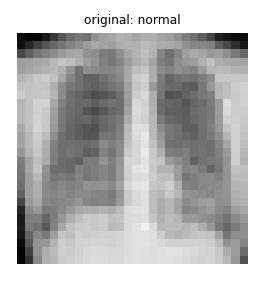

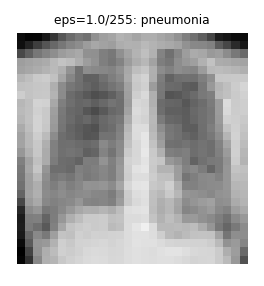

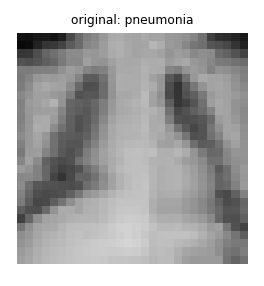

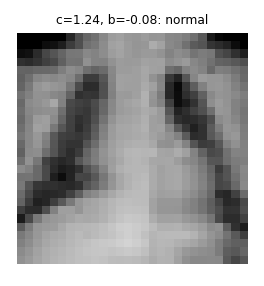


== hardened: čista tačnost 0.885
  L-inf 1.0/255: PGD 0.805, dokazano 0.805
  L-inf 2.0/255: PGD 0.775, dokazano 0.770
  kontrast [0.7, 1.3], osvetljenje [-0.15, 0.15]: napad 0.825, dokazano 0.825, {'certified': 165, 'falsified': 2, 'unknown': 0, 'misclassified': 33}


/tmp/ipykernel_1893/1994168861.py:4: ResourceWarning: unclosed file <_io.TextIOWrapper name='/content/drive/MyDrive/robust/results/hardened/results.json' mode='r' encoding='utf-8'>
  r = json.load(open(f'{OUT}/results/{name}/results.json'))


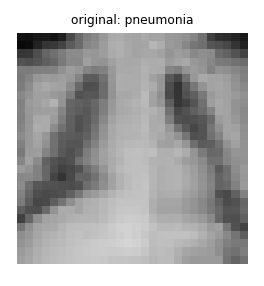

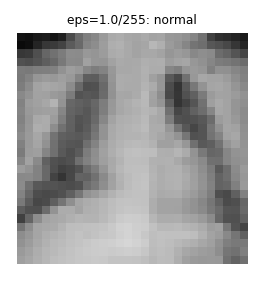

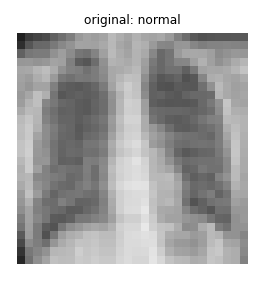

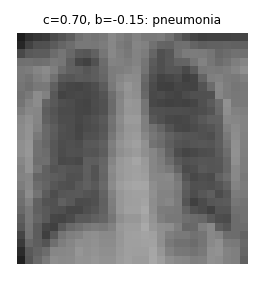

In [ ]:
import json, os
from IPython.display import Image, display
for name in ['baseline', 'hardened']:
    r = json.load(open(f'{OUT}/results/{name}/results.json'))
    print(f"\n== {name}: čista tačnost {r['model']['clean_accuracy']:.3f}")
    for row in r['linf']:
        print(f"  L-inf {row['eps_255']}/255: PGD {row['pgd_acc']:.3f}, dokazano {row['certified_acc']:.3f}")
    a = r['acquisition']
    print(f"  kontrast {a['contrast']}, osvetljenje {a['brightness']}: napad {a['attack_acc']:.3f}, dokazano {a['certified_acc']:.3f}, {a['counts']}")
    for ex in [r.get('linf_example'), a.get('example')]:
        if ex:
            display(Image(f"{OUT}/results/{name}/{ex['clean_png']}")); display(Image(f"{OUT}/results/{name}/{ex['adv_png']}"))

In [ ]:
   %%writefile report.py
   """HTML izvestaj (paket dokaza) iz dva results.json: referentni i kandidat model.

  python report.py --baseline results/baseline --candidate results/hardened --out report.html [--lang sr|en]

Izlaz je jedan samostalan HTML fajl (slike su ugradjene), spreman za browser ili stampu u PDF.
"""
import argparse
import base64
import html
import json
import os

T = {
    "en": {
        "title": "Robustness Evidence Report",
        "sub": "Formal verification of a neural network under acquisition and adversarial perturbations",
        "under_test": "Model under test", "reference": "Reference model", "dataset": "Dataset",
        "created": "Generated", "verdict": "Result",
        "verdict_txt": "Proven robust on {c} of {n} correctly classified test images ({p}) for contrast {cr} and brightness {br}. "
                       "{fx} Undecided: {u}.",
        "vs_ref": "Reference model: {c} of {n} ({p}), {f} counterexamples.",
        "acc": "Accuracy (full test set)", "acq_title": "Acquisition robustness (contrast and brightness)",
        "acq_desc": "Specification: x' = c·(x − mean(x)) + mean(x) + b for every contrast factor c in {cr} and brightness shift b in {br}. "
                    "A certificate is a mathematical proof that no setting in this range changes the diagnosis.",
        "certified": "Certified", "falsified": "Counterexample", "unknown": "Undecided", "misclassified": "Misclassified",
        "linf_title": "Adversarial robustness (L∞)",
        "linf_desc": "Every image within distance ε (per pixel) of the original. Attack = PGD; proof = CROWN bound propagation.",
        "eps": "ε", "attack": "Robust under attack", "proof": "Proven robust", "model": "Model",
        "cex_title": "Counterexamples", "cex_desc": "Inputs that change the model's decision. Left: original, right: perturbed.",
        "cex_list": "Remaining counterexamples of the model under test",
        "idx": "Test image", "label": "Label", "pred_after": "Prediction after perturbation", "c": "Contrast c", "b": "Brightness b",
        "reg_title": "Mapping to requirements",
        "reg_rows": [
            ("EU AI Act, Art. 15(5)", "Resilience against inputs designed to cause the model to make a mistake (adversarial examples, model evasion)", "Adversarial robustness (L∞)"),
            ("EU AI Act, Art. 15(4)", "Resilience regarding errors, faults or inconsistencies in the environment of use", "Acquisition robustness (contrast, brightness)"),
            ("ISO/IEC 24029-2:2023", "Methodology for formal methods in robustness assessment of neural networks", "Methods section"),
        ],
        "reg_cols": ("Requirement", "What it asks", "Evidence in this report"),
        "methods_title": "Methods and limitations",
        "methods": [
            "L∞ proofs: CROWN linear bound propagation (auto_LiRPA). Attacks: PGD with random restarts.",
            "Acquisition proofs: forward linear relaxation over the two acquisition parameters with branch-and-bound over the parameter box. Every image ends as proven, counterexample, or undecided.",
            "Soundness check of the verifier: no proven image was broken by attack; on 100 random parameter boxes with 2,000 samples each, no true margin fell below the computed bound.",
            "Results hold for the stated ranges, the evaluated test images and this model version; they are not a claim of regulatory conformity.",
            "The acquisition model is linear and ignores sensor saturation; ranges should be set from the intended clinical acquisition conditions.",
        ],
        "fx_some": "{f} counterexamples found and listed below.", "fx_none": "No counterexamples found.",
        "sample_note": "Evaluated on {n} test images sampled with a fixed seed.",
    },
    "sr": {
        "title": "Izveštaj o robusnosti",
        "sub": "Formalna verifikacija neuronske mreže pod perturbacijama snimanja i adversarial napadima",
        "under_test": "Model koji se proverava", "reference": "Referentni model", "dataset": "Dataset",
        "created": "Napravljeno", "verdict": "Rezultat",
        "verdict_txt": "Dokazana robusnost na {c} od {n} tačno klasifikovanih test snimaka ({p}) za kontrast {cr} i osvetljenje {br}. "
                       "{fx} Neodlučenih: {u}.",
        "vs_ref": "Referentni model: {c} od {n} ({p}), {f} kontraprimera.",
        "acc": "Tačnost (ceo test skup)", "acq_title": "Robusnost na parametre snimanja (kontrast i osvetljenje)",
        "acq_desc": "Specifikacija: x' = c·(x − mean(x)) + mean(x) + b za svaki faktor kontrasta c u {cr} i pomeraj osvetljenja b u {br}. "
                    "Sertifikat je matematički dokaz da nijedno podešavanje u tom opsegu ne menja dijagnozu.",
        "certified": "Dokazano", "falsified": "Kontraprimer", "unknown": "Neodlučeno", "misclassified": "Pogrešno klasifikovano",
        "linf_title": "Adversarial robusnost (L∞)",
        "linf_desc": "Svaka slika na rastojanju najviše ε po pikselu od originala. Napad = PGD; dokaz = CROWN.",
        "eps": "ε", "attack": "Robusno pod napadom", "proof": "Dokazano robusno", "model": "Model",
        "cex_title": "Kontraprimeri", "cex_desc": "Ulazi koji menjaju odluku modela. Levo: original, desno: izmenjen snimak.",
        "cex_list": "Preostali kontraprimeri modela koji se proverava",
        "idx": "Test snimak", "label": "Oznaka", "pred_after": "Predikcija posle izmene", "c": "Kontrast c", "b": "Osvetljenje b",
        "reg_title": "Mapiranje na zahteve",
        "reg_rows": [
            ("EU AI Act, Član 15(5)", "Otpornost na ulaze dizajnirane da navedu model na grešku (adversarial primeri, model evasion)", "Adversarial robusnost (L∞)"),
            ("EU AI Act, Član 15(4)", "Otpornost na greške i nedoslednosti u okruženju upotrebe", "Robusnost na parametre snimanja"),
            ("ISO/IEC 24029-2:2023", "Metodologija formalnih metoda za procenu robusnosti neuronskih mreža", "Sekcija o metodama"),
        ],
        "reg_cols": ("Zahtev", "Šta traži", "Dokaz u ovom izveštaju"),
        "methods_title": "Metode i ograničenja",
        "methods": [
            "L∞ dokazi: CROWN propagacija linearnih granica (auto_LiRPA). Napadi: PGD sa nasumičnim restartima.",
            "Dokazi za snimanje: forward linearna relaksacija po dva parametra snimanja uz branch-and-bound po kutiji parametara. Svaka slika završava kao dokazana, kontraprimer ili neodlučena.",
            "Provera ispravnosti verifikatora: nijedna dokazana slika nije oborena napadom; na 100 nasumičnih kutija sa po 2.000 tačaka stvarna margina nijednom nije pala ispod izračunate granice.",
            "Rezultati važe za navedene opsege, proverene test snimke i ovu verziju modela; ovo nije tvrdnja o regulatornoj usaglašenosti.",
            "Model snimanja je linearan i zanemaruje zasićenje senzora; opsege treba odrediti iz predviđenih kliničkih uslova snimanja.",
        ],
        "fx_some": "Pronađeno {f} kontraprimera, navedeni su ispod.", "fx_none": "Nije pronađen nijedan kontraprimer.",
        "sample_note": "Provereno na {n} test snimaka izabranih sa fiksnim seed-om.",
    },
}

CSS = """
:root{--ink:#1d1d1b;--quiet:#5f5e5a;--line:#e3e1db;--bg:#faf9f6;--good:#2e7d4f;--bad:#c0392b;--mid:#b7791f;--grey:#9a978f;--accent:#1f5fa8}
*{box-sizing:border-box}body{margin:0;background:var(--bg);color:var(--ink);font:15px/1.55 -apple-system,BlinkMacSystemFont,"Segoe UI",Inter,Helvetica,Arial,sans-serif}
main{max-width:920px;margin:0 auto;padding:48px 32px 64px}
h1{font-size:28px;margin:0 0 4px;letter-spacing:-.01em}h2{font-size:19px;margin:40px 0 8px}
.sub{color:var(--quiet);margin:0 0 24px}.meta{display:grid;grid-template-columns:repeat(4,1fr);gap:12px;border-top:1px solid var(--line);border-bottom:1px solid var(--line);padding:14px 0;font-size:13px}
.meta b{display:block;color:var(--quiet);font-weight:500;font-size:11.5px;text-transform:uppercase;letter-spacing:.04em}
.verdict{margin:28px 0;padding:20px 24px;background:#fff;border:1px solid var(--line);border-left:4px solid var(--good);border-radius:8px}
.verdict .big{font-size:40px;font-weight:700;color:var(--good);line-height:1}.verdict p{margin:8px 0 0}.verdict .ref{color:var(--quiet);font-size:13.5px}
p.desc{color:var(--quiet);margin:0 0 14px;font-size:14px}
table{width:100%;border-collapse:collapse;background:#fff;border:1px solid var(--line);border-radius:8px;overflow:hidden;font-size:14px}
th,td{text-align:left;padding:9px 12px;border-bottom:1px solid var(--line)}th{background:#f3f1ec;font-weight:600;font-size:12.5px;color:var(--quiet)}
td.num{text-align:right;font-variant-numeric:tabular-nums}.nums th:not(:first-child){text-align:right}tr:last-child td{border-bottom:none}
.bars{display:grid;gap:12px;margin:8px 0 4px}.bar-row{display:grid;grid-template-columns:200px 1fr;align-items:center;gap:12px;font-size:13.5px}
.bar{display:flex;height:26px;border-radius:6px;overflow:hidden;background:#eee}.bar span{display:flex;align-items:center;justify-content:center;color:#fff;font-size:12px;font-weight:600;white-space:nowrap}
.legend{display:flex;gap:16px;font-size:12.5px;color:var(--quiet);margin:8px 0 0}.legend i{display:inline-block;width:10px;height:10px;border-radius:2px;margin-right:6px;vertical-align:-1px}
.cex{display:grid;grid-template-columns:1fr 1fr;gap:16px}.card{background:#fff;border:1px solid var(--line);border-radius:8px;padding:12px}
.card h3{font-size:13.5px;margin:0 0 8px}.pair{display:flex;gap:8px}.pair img{width:50%;border-radius:4px;image-rendering:pixelated}
ul{padding-left:20px}li{margin:4px 0}.foot{margin-top:40px;color:var(--grey);font-size:12px}
@media print{body{background:#fff}main{padding:0}.verdict,table,.card{break-inside:avoid}}
"""


def load(d):
    with open(os.path.join(d, "results.json")) as f:
        return json.load(f)


def img64(d, rel):
    p = os.path.join(d, rel)
    if not rel or not os.path.exists(p):
        return None
    with open(p, "rb") as f:
        return "data:image/png;base64," + base64.b64encode(f.read()).decode()


def pct(x):
    return f"{100 * x:.1f}%".replace(".0%", "%")


def rng(r, kind):
    lo, hi = r
    if kind == "c":
        return f"[{lo:g}, {hi:g}] (±{round(100 * (hi - 1))}%)" if abs((hi - 1) + (lo - 1)) < 1e-9 else f"[{lo:g}, {hi:g}]"
    return f"[{lo:+g}, {hi:+g}] (±{round(100 * hi)}%)" if abs(hi + lo) < 1e-9 else f"[{lo:+g}, {hi:+g}]"


def acq_stats(r):
    c = r["acquisition"]["counts"]
    correct = c["certified"] + c["falsified"] + c["unknown"]
    return c, correct


def bar(label, counts, total, t):
    colors = {"certified": "var(--good)", "falsified": "var(--bad)", "unknown": "var(--mid)", "misclassified": "var(--grey)"}
    parts = ""
    for k in ["certified", "falsified", "unknown", "misclassified"]:
        v = counts.get(k, 0)
        if v:
            w = 100 * v / total
            txt = str(v) if w > 4 else ""
            parts += f'<span style="width:{w:.2f}%;background:{colors[k]}" title="{t[k]}: {v}">{txt}</span>'
    return f'<div class="bar-row"><div>{html.escape(label)}</div><div class="bar">{parts}</div></div>'


def build(base_dir, cand_dir, lang="en"):
    t = T[lang]
    b, c = load(base_dir), load(cand_dir)
    e = html.escape
    acq = c["acquisition"]
    cr, br = rng(acq["contrast"], "c"), rng(acq["brightness"], "b")
    cc, cn = acq_stats(c)
    bc, bn = acq_stats(b)
    bname, cname = b["model"]["name"], c["model"]["name"]

    verdict = t["verdict_txt"].format(c=cc["certified"], n=cn, p=pct(cc["certified"] / max(cn, 1)), cr=cr, br=br,
                                      fx=(t['fx_some'].format(f=cc['falsified']) if cc['falsified'] else t['fx_none']), u=cc["unknown"])
    vref = t["vs_ref"].format(c=bc["certified"], n=bn, p=pct(bc["certified"] / max(bn, 1)), f=bc["falsified"])

    rows_acq = "".join(
        f"<tr><td>{e(r['model']['name'])}</td><td class=num>{pct(r['model']['clean_accuracy'])}</td>"
        f"<td class=num>{s[0]['certified']} / {s[1]} ({pct(s[0]['certified'] / max(s[1], 1))})</td>"
        f"<td class=num>{s[0]['falsified']}</td><td class=num>{s[0]['unknown']}</td></tr>"
        for r, s in [(b, (bc, bn)), (c, (cc, cn))])

    ntot = c["verifier"]["n_samples"]
    bars = bar(bname, bc, b["verifier"]["n_samples"], t) + bar(cname, cc, ntot, t)
    legend = "".join(f'<span><i style="background:{col}"></i>{t[k]}</span>' for k, col in
                     [("certified", "var(--good)"), ("falsified", "var(--bad)"), ("unknown", "var(--mid)"),
                      ("misclassified", "var(--grey)")])

    rows_linf = ""
    for r in [b, c]:
        for row in r["linf"]:
            rows_linf += (f"<tr><td>{e(r['model']['name'])}</td><td class=num>{row['eps_255']:g}/255</td>"
                          f"<td class=num>{pct(row['pgd_acc'])}</td><td class=num>{pct(row['certified_acc'])}</td></tr>")

    cards = ""
    for r, d in [(b, base_dir), (c, cand_dir)]:
        ex = r.get("linf_example")
        if ex:
            a, z = img64(d, ex["clean_png"]), img64(d, ex["adv_png"])
            if a and z:
                cards += (f'<div class="card"><h3>{e(r["model"]["name"])} · L∞ ε={ex["eps"] * 255:.1f}/255: '
                          f'{e(ex["label"])} → {e(ex["adv_pred"])}</h3><div class="pair"><img src="{a}"><img src="{z}"></div></div>')
        ex = r["acquisition"].get("example")
        if ex:
            a, z = img64(d, ex["clean_png"]), img64(d, ex["adv_png"])
            if a and z:
                cards += (f'<div class="card"><h3>{e(r["model"]["name"])} · c={ex["contrast"]:.2f}, b={ex["brightness"]:+.2f}: '
                          f'{e(ex["label"])} → {e(ex["pred"])}</h3><div class="pair"><img src="{a}"><img src="{z}"></div></div>')

    cex_rows = "".join(
        f"<tr><td class=num>{s['index']}</td><td>{e(s['label'])}</td><td>{e(s['acquisition']['counterexample']['pred'])}</td>"
        f"<td class=num>{s['acquisition']['counterexample']['contrast']:.3f}</td>"
        f"<td class=num>{s['acquisition']['counterexample']['brightness']:+.3f}</td></tr>"
        for s in c["samples"] if s["acquisition"] and s["acquisition"].get("counterexample"))
    cex_table = (f"<h3 style='font-size:15px;margin:24px 0 8px'>{t['cex_list']}</h3><table><tr><th>{t['idx']}</th><th>{t['label']}</th>"
                 f"<th>{t['pred_after']}</th><th>{t['c']}</th><th>{t['b']}</th></tr>{cex_rows}</table>") if cex_rows else ""

    reg = "".join(f"<tr><td><b>{e(a)}</b></td><td>{e(q)}</td><td>{e(w)}</td></tr>" for a, q, w in t["reg_rows"])
    meth = "".join(f"<li>{e(m)}</li>" for m in t["methods"])

    return f"""<!DOCTYPE html><html lang="{lang}"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>{t['title']} · {e(cname)}</title><style>{CSS}</style></head><body><main>
<h1>{t['title']}</h1><p class="sub">{t['sub']}</p>
<div class="meta"><div><b>{t['under_test']}</b>{e(cname)}</div><div><b>{t['reference']}</b>{e(bname)}</div>
<div><b>{t['dataset']}</b>{e(c['data']['dataset'])}</div><div><b>{t['created']}</b>{e(c['created'][:16].replace('T', ' '))}</div></div>
<div class="verdict"><div class="big">{pct(cc['certified'] / max(cn, 1))}</div><p>{e(verdict)}</p><p class="ref">{e(vref)}</p></div>

<h2>{t['acq_title']}</h2><p class="desc">{e(t['acq_desc'].format(cr=cr, br=br))}</p>
<div class="bars">{bars}</div><div class="legend">{legend}</div>
<table class="nums" style="margin-top:16px"><tr><th>{t['model']}</th><th>{t['acc']}</th><th>{t['certified']}</th><th>{t['falsified']}</th><th>{t['unknown']}</th></tr>{rows_acq}</table>

<h2>{t['linf_title']}</h2><p class="desc">{t['linf_desc']}</p>
<table class="nums"><tr><th>{t['model']}</th><th>{t['eps']}</th><th>{t['attack']}</th><th>{t['proof']}</th></tr>{rows_linf}</table>

<h2>{t['cex_title']}</h2><p class="desc">{t['cex_desc']}</p><div class="cex">{cards}</div>{cex_table}

<h2>{t['reg_title']}</h2><table><tr><th>{t['reg_cols'][0]}</th><th>{t['reg_cols'][1]}</th><th>{t['reg_cols'][2]}</th></tr>{reg}</table>

<h2>{t['methods_title']}</h2><ul>{meth}</ul>
<p class="foot">{e(t['sample_note'].format(n=ntot))} · {e(c['verifier'].get('linf', ''))} · {e(c['verifier'].get('acquisition', ''))}</p>
</main></body></html>"""


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--baseline", required=True)
    ap.add_argument("--candidate", required=True)
    ap.add_argument("--out", default="report.html")
    ap.add_argument("--lang", default="en", choices=["en", "sr"])
    a = ap.parse_args()
    with open(a.out, "w", encoding="utf-8") as f:
        f.write(build(a.baseline, a.candidate, a.lang))
    print(f"Sacuvano: {a.out}")


if __name__ == "__main__":
    main()


Writing report.py


In [ ]:
!python report.py --baseline $OUT/results/baseline --candidate $OUT/results/hardened --out $OUT/report_sr.html --lang sr
!python report.py --baseline $OUT/results/baseline --candidate $OUT/results/hardened --out $OUT/report_en.html --lang en
from google.colab import files
files.download(f'{OUT}/report_sr.html')

Sacuvano: /content/drive/MyDrive/robust/report_sr.html
Sacuvano: /content/drive/MyDrive/robust/report_en.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%%writefile demo.py

"""Demo stranica za pitch: jedan samostalan HTML (bez interneta, bez Colab-a).

  python demo.py --baseline models/baseline.pt --candidate models/hardened.pt \
                 --rb results/baseline --rc results/hardened --out demo.html [--lang sr|en] [--synthetic]

Tri ekrana (strelice levo/desno ili dugmad):
  1. udica: original i adversarial snimak koji izgledaju isto, a dijagnoza je druga
  2. klizaci za kontrast i osvetljenje + mapa opsega za verziju 1 i verziju 2 + rezultat dokaza
  3. brojevi iz results.json i link na izvestaj
"""
import argparse
import json
import os

import numpy as np
import torch
import torch.nn.functional as F
import yaml

import core

GRID = 41
DEPTH = 5


def load_model(path, dev):
    m = core.make_model().to(dev)
    m.load_state_dict(torch.load(path, map_location=dev))
    return m.eval()


@torch.no_grad()
def proof_map(model, x, y, c_rng, b_rng, dev, depth=DEPTH):
    """Branch-and-bound nad kutijom parametara jedne slike; vraca listove sa statusom.
    Za razliku od Verifier-a, ne staje na prvom kontraprimeru, da bi mapa bila potpuna."""
    leaves, boxes = [], [(c_rng[0], c_rng[1], b_rng[0], b_rng[1], 0)]
    yy = torch.tensor([y], device=dev)
    while boxes:
        pl = torch.tensor([[b[0], b[2]] for b in boxes], device=dev)
        pu = torch.tensor([[b[1], b[3]] for b in boxes], device=dev)
        lb = core.forward_linear_margin(model, x.expand(len(boxes), -1, -1, -1), yy.expand(len(boxes)), pl, pu)
        nxt = []
        for bx, v in zip(boxes, lb.tolist()):
            cl, cu, bl, bu, d = bx
            if v > 0:
                leaves.append([cl, cu, bl, bu, "proven"])
                continue
            cm, bm = (cl + cu) / 2, (bl + bu) / 2
            pred = model(core.acquire(x, torch.tensor([cm], device=dev), torch.tensor([bm], device=dev))).argmax(1).item()
            if d >= depth:
                leaves.append([cl, cu, bl, bu, "counterexample" if pred != y else "open"])
            else:
                nxt += [(cl, cm, bl, bm, d + 1), (cm, cu, bl, bm, d + 1), (cl, cm, bm, bu, d + 1), (cm, cu, bm, bu, d + 1)]
        boxes = nxt
    area = (c_rng[1] - c_rng[0]) * (b_rng[1] - b_rng[0])
    proven = sum((l[1] - l[0]) * (l[3] - l[2]) for l in leaves if l[4] == "proven") / area
    return [[round(v, 5) if isinstance(v, float) else v for v in l] for l in leaves], proven


@torch.no_grad()
def grid_preds(model, x, cs, bs):
    C, B = torch.meshgrid(cs, bs, indexing="ij")
    xs = core.acquire(x.expand(C.numel(), -1, -1, -1), C.reshape(-1), B.reshape(-1))
    p = F.softmax(model(xs), 1)[:, 1]  # verovatnoca pneumonije
    return p.reshape(len(cs), len(bs))


def pick_images(m1, m2, X, y, c_rng, b_rng, dev, n=3):
    """Snimci koje oba modela tacno klasifikuju, a v1 ima kontraprimer u opsegu.
    Prednost: pneumonija i kontraprimer blizu identiteta (najubedljivije)."""
    x = torch.from_numpy(X).to(dev)
    t = torch.from_numpy(y).to(dev)
    with torch.no_grad():
        ok = (m1(x).argmax(1) == t) & (m2(x).argmax(1) == t)
    cand = ok.nonzero().flatten()[:600]
    fooled, cx, bx, _ = core.acquisition_attack(m1, x[cand], t[cand], c_rng, b_rng, grid=21)
    fooled2, *_ = core.acquisition_attack(m2, x[cand], t[cand], c_rng, b_rng, grid=21)
    good = [(int(cand[i]), float(abs(cx[i] - 1) + abs(bx[i]))) for i in range(len(cand)) if fooled[i] and not fooled2[i]]
    good.sort(key=lambda g: -g[1])  # "veca" crvena oblast prvo
    pn = [g[0] for g in good if y[g[0]] == 1]
    no = [g[0] for g in good if y[g[0]] == 0]
    # mesavina: bar jedan normalan snimak (ako postoji), ostalo pneumonija
    n_no = min(len(no), max(1, n // 3)) if no else 0
    picked = pn[:n - n_no] + no[:n_no]
    for g in pn[n - n_no:] + no[n_no:]:          # dopuni ako neke klase nema dovoljno
        if len(picked) >= n:
            break
        picked.append(g)
    return picked


def pick_hook(m1, X, y, dev):
    x = torch.from_numpy(X[:800]).to(dev)
    t = torch.from_numpy(y[:800]).to(dev)
    with torch.no_grad():
        ok = m1(x).argmax(1) == t
    for eps in [1 / 255, 2 / 255, 4 / 255, 8 / 255, 16 / 255]:
        adv = core.pgd_linf(m1, x, t, eps, steps=60, restarts=3)
        with torch.no_grad():
            flip = (m1(adv).argmax(1) != t) & ok
        idx = flip.nonzero().flatten().tolist()
        if idx:
            idx.sort(key=lambda i: -int(y[i] == 1))
            i = idx[0]
            with torch.no_grad():
                p0 = F.softmax(m1(x[i:i + 1]), 1)[0].tolist()
                p1 = F.softmax(m1(adv[i:i + 1]), 1)[0].tolist()
            return {"eps255": round(eps * 255, 1), "label": int(y[i]),
                    "x": np.round(X[i, 0], 4).tolist(), "adv": np.round(adv[i, 0].cpu().numpy(), 4).tolist(),
                    "p_orig": p0, "p_adv": p1}
    return None


def summary(d):
    if not d or not os.path.exists(os.path.join(d, "results.json")):
        return None
    r = json.load(open(os.path.join(d, "results.json")))
    c = r["acquisition"]["counts"]
    correct = c["certified"] + c["falsified"] + c["unknown"]
    return {"acc": r["model"]["clean_accuracy"], "certified": c["certified"], "correct": correct,
            "falsified": c["falsified"], "unknown": c["unknown"], "n": r["verifier"]["n_samples"],
            "linf": r["linf"]}


def build_data(args):
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    spec = yaml.safe_load(open(args.spec))["verify"]
    c_rng, b_rng = spec["contrast"], spec["brightness"]
    X, y = core.load_data(synthetic=args.synthetic)["test"]
    m1, m2 = load_model(args.baseline, dev), load_model(args.candidate, dev)
    cs = torch.linspace(*c_rng, GRID, device=dev)
    bs = torch.linspace(*b_rng, GRID, device=dev)
    imgs = []
    for i in pick_images(m1, m2, X, y, c_rng, b_rng, dev, n=args.n):
        x = torch.from_numpy(X[i:i + 1]).to(dev)
        item = {"index": i, "label": int(y[i]), "x": np.round(X[i, 0], 4).tolist(), "models": []}
        for m in (m1, m2):
            leaves, proven = proof_map(m, x, int(y[i]), c_rng, b_rng, dev)
            item["models"].append({"p": np.round(grid_preds(m, x, cs, bs).cpu().numpy(), 4).tolist(),
                                   "leaves": leaves, "proven_area": proven})
        imgs.append(item)
        print(f"  snimak {i}: v1 dokazano {item['models'][0]['proven_area']:.0%} oblasti, "
              f"v2 dokazano {item['models'][1]['proven_area']:.0%} oblasti")
    return {"contrast": c_rng, "brightness": b_rng, "grid": GRID, "classes": core.CLASSES,
            "hook": pick_hook(m1, X, y, dev), "images": imgs,
            "summary": [summary(args.rb), summary(args.rc)], "report": args.report_link}


TEXT = {
    "sr": {"classes": ["Normalno", "Pneumonija"], "s1t": "Isti snimak. Druga dijagnoza.",
           "s1d": "Promena od najviše {eps}/255 po pikselu. {vis}", "vis_lo": "Oko je ne vidi, a model menja dijagnozu.", "vis_hi": "Jedva primetna, a model menja dijagnozu.",
           "orig": "Original", "adv": "Izmenjen", "diff": "Razlika (pojačana)", "conf": "sigurnost",
           "s2t": "Test proverava tačke. Mi dokazujemo celu oblast.",
           "s2d": "Svako podešavanje skenera u opsegu kontrasta {cr} i osvetljenja {br}.",
           "contrast": "Kontrast", "brightness": "Osvetljenje", "v1": "Verzija 1", "v2": "Verzija 2",
           "proven_all": "DOKAZANO za ceo opseg", "not_proven": "NIJE DOKAZANO",
           "cex": "kontraprimer", "proven_area": "dokazano {p} oblasti",
           "legend": ["test prošao, nije dokazano", "dijagnoza promenjena (kontraprimer)", "dokazano: dijagnoza ne može da se promeni"],
           "s3t": "Dokaz za auditora, za svaku verziju modela.",
           "certified": "dokazano robusno", "cexs": "kontraprimera", "acc": "tačnost",
           "of": "od", "report": "Otvori izveštaj za auditora →", "image": "Snimak",
           "foot": "PneumoniaMNIST · 200 test snimaka · formalna verifikacija (linearne granice + branch-and-bound)"},
    "en": {"classes": ["Normal", "Pneumonia"], "s1t": "Same scan. Different diagnosis.",
           "s1d": "A change of at most {eps}/255 per pixel. {vis}", "vis_lo": "Invisible to the eye, yet it flips the diagnosis.", "vis_hi": "Barely visible, yet it flips the diagnosis.",
           "orig": "Original", "adv": "Perturbed", "diff": "Difference (amplified)", "conf": "confidence",
           "s2t": "Testing checks points. We prove the whole region.",
           "s2d": "Every scanner setting with contrast in {cr} and brightness in {br}.",
           "contrast": "Contrast", "brightness": "Brightness", "v1": "Version 1", "v2": "Version 2",
           "proven_all": "PROVEN for the whole range", "not_proven": "NOT PROVEN",
           "cex": "counterexample", "proven_area": "{p} of the region proven",
           "legend": ["test passed, not proven", "diagnosis changed (counterexample)", "proven: diagnosis cannot change"],
           "s3t": "Evidence for the auditor, for every model version.",
           "certified": "proven robust", "cexs": "counterexamples", "acc": "accuracy",
           "of": "of", "report": "Open the auditor report →", "image": "Scan",
           "foot": "PneumoniaMNIST · 200 test scans · formal verification (linear bounds + branch-and-bound)"},
}

PAGE = r"""<!DOCTYPE html><html lang="__LANG__"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>Robustness demo</title><style>
:root{--bg:#0f1115;--panel:#171a21;--line:#2a2f3a;--ink:#f2f3f5;--quiet:#9aa3b2;--good:#3fbf7f;--bad:#ef5350;--amber:#f0b23e;--accent:#7aa7ff}
*{box-sizing:border-box}html,body{margin:0;height:100%;background:var(--bg);color:var(--ink);font:16px/1.5 Inter,-apple-system,"Segoe UI",Helvetica,Arial,sans-serif}
.slide{display:none;min-height:100vh;padding:4vh 5vw 4vh;flex-direction:column;justify-content:center}.slide.on{display:flex}
h1{font-size:clamp(26px,3vw,48px);line-height:1.1;margin:0 0 .3em;letter-spacing:-.02em}.lead{color:var(--quiet);font-size:clamp(14px,1.2vw,20px);margin:0 0 3vh}
.row{display:flex;gap:3vw;align-items:flex-start;justify-content:center}.fig{text-align:center}
canvas.img{width:min(24vw,40vh);height:min(24vw,40vh);image-rendering:pixelated;border-radius:10px;display:block;background:#000}
.tag{display:inline-block;margin-top:14px;padding:8px 18px;border-radius:999px;font-weight:700;font-size:clamp(16px,1.5vw,24px)}
.tag.pn{background:rgba(239,83,80,.16);color:#ff8a85}.tag.no{background:rgba(63,191,127,.16);color:#7fe0ad}
.cap{color:var(--quiet);font-size:14px;margin-top:6px}.arrow{align-self:center;font-size:40px;color:var(--quiet);margin-top:-8vh}
.s2{display:grid;grid-template-columns:min(20vw,32vh) auto auto;gap:2.4vw;align-items:start;justify-content:center}
.left{display:flex;flex-direction:column;gap:14px;align-items:center}.left canvas.img{width:min(17vw,26vh);height:min(17vw,26vh)}
.ctl{width:100%}.ctl label{display:flex;justify-content:space-between;color:var(--quiet);font-size:14px}.ctl b{color:var(--ink);font-variant-numeric:tabular-nums}
input[type=range]{width:100%;accent-color:var(--accent)}
.thumbs{display:flex;gap:8px}.thumbs canvas{width:46px;height:46px;image-rendering:pixelated;border-radius:6px;cursor:pointer;opacity:.5;border:2px solid transparent}.thumbs canvas.sel{opacity:1;border-color:var(--accent)}
.card{background:var(--panel);border:1px solid var(--line);border-radius:14px;padding:18px}
.card h2{margin:0 0 10px;font-size:clamp(16px,1.4vw,22px);display:flex;justify-content:space-between;align-items:center}
.card canvas.map{width:min(25vw,40vh);height:min(25vw,40vh);border-radius:8px;display:block;cursor:crosshair}.s2 .card{width:calc(min(25vw,40vh) + 32px);padding:14px 16px}
.dx{margin-top:8px;font-size:clamp(15px,1.3vw,20px)}.verdict{margin-top:10px;padding:10px 14px;border-radius:10px;font-weight:800;font-size:clamp(15px,1.35vw,21px)}
.verdict.ok{background:rgba(63,191,127,.15);color:#7fe0ad}.verdict.bad{background:rgba(239,83,80,.15);color:#ff8a85}.verdict small{display:block;font-weight:500;font-size:13px;opacity:.9}
.axes{display:flex;justify-content:space-between;color:var(--quiet);font-size:12px;margin-top:4px}
.legend{display:flex;gap:18px;color:var(--quiet);font-size:13px;margin-top:1.6vh;justify-content:center}.legend i{display:inline-block;width:12px;height:12px;border-radius:3px;margin-right:6px;vertical-align:-1px}
.big{display:grid;grid-template-columns:1fr 1fr;gap:3vw;max-width:1100px;margin:0 auto;width:100%}
.big .card{padding:3vh 2.4vw}.num{font-size:clamp(48px,6vw,96px);font-weight:800;line-height:1;letter-spacing:-.03em}
.num.ok{color:var(--good)}.num.bad{color:var(--amber)}.sub{color:var(--quiet);margin-top:8px;font-size:clamp(14px,1.2vw,19px)}
.stat{display:flex;gap:2vw;margin-top:2.4vh;font-size:clamp(14px,1.2vw,18px)}.stat b{display:block;font-size:clamp(22px,2.2vw,34px)}
a.btn{display:inline-block;margin:4vh auto 0;padding:14px 26px;border-radius:12px;background:var(--accent);color:#0b1020;font-weight:800;text-decoration:none;font-size:clamp(15px,1.3vw,20px)}
.nav{position:fixed;bottom:2vh;right:2vw;display:flex;gap:8px;opacity:.55}.nav:hover{opacity:1}.nav button{background:var(--panel);color:var(--ink);border:1px solid var(--line);border-radius:999px;padding:8px 16px;font:inherit;cursor:pointer}
.dots{display:flex;gap:8px;align-items:center}.dots span{width:8px;height:8px;border-radius:50%;background:var(--line)}.dots span.on{background:var(--accent)}
.foot{position:fixed;bottom:1vh;right:2vw;color:#5b6475;font-size:12px}
</style></head><body>
<section class="slide" id="s1"></section><section class="slide" id="s2"></section><section class="slide" id="s3"></section>
<div class="nav"><button id="prev">←</button><div class="dots"><span></span><span></span><span></span></div><button id="next">→</button></div>

<script>
const D = __DATA__, T = __TEXT__;
const $ = s => document.querySelector(s);
const fmtPct = v => (Math.round(v * 1000) / 10).toString().replace('.', T.classes[0] === 'Normalno' ? ',' : '.') + '%';
const fmtR = (r, sign) => '[' + r.map(v => (sign && v > 0 ? '+' : '') + v).join(', ') + ']';
function drawImg(cv, px, c = 1, b = 0, scale = 1) {
  const n = px.length, ctx = cv.getContext('2d'); cv.width = n; cv.height = n;
  let m = 0; px.forEach(r => r.forEach(v => m += v)); m /= n * n;
  const im = ctx.createImageData(n, n);
  for (let i = 0; i < n; i++) for (let j = 0; j < n; j++) {
    let v = c * (px[i][j] - m) + m + b; v = Math.max(0, Math.min(1, v * scale));
    const k = 4 * (i * n + j); im.data[k] = im.data[k + 1] = im.data[k + 2] = Math.round(v * 255); im.data[k + 3] = 255;
  }
  ctx.putImageData(im, 0, 0);
}
function tag(cls) { return `<span class="tag ${cls ? 'pn' : 'no'}">${T.classes[cls]}</span>`; }

// ---------- slide 1
(function () {
  const h = D.hook, s = $('#s1');
  if (!h) { s.innerHTML = `<h1>${T.s1t}</h1>`; return; }
  const c0 = h.p_orig[1] > .5 ? 1 : 0, c1 = h.p_adv[1] > .5 ? 1 : 0;
  s.innerHTML = `<h1>${T.s1t}</h1><p class="lead">${T.s1d.replace('{eps}', h.eps255).replace('{vis}', h.eps255 <= 2 ? T.vis_lo : T.vis_hi)}</p>
  <div class="row"><div class="fig"><canvas class="img" id="h0"></canvas>${tag(c0)}<div class="cap">${T.orig} · ${T.conf} ${fmtPct(Math.max(...h.p_orig))}</div></div>
  <div class="arrow">→</div>
  <div class="fig"><canvas class="img" id="h1"></canvas>${tag(c1)}<div class="cap">${T.adv} · ${T.conf} ${fmtPct(Math.max(...h.p_adv))}</div></div>
  <div class="fig"><canvas class="img" id="h2"></canvas><div class="cap" style="margin-top:18px">${T.diff}</div></div></div>`;
  drawImg($('#h0'), h.x); drawImg($('#h1'), h.adv);
  const k = 0.45 / (h.eps255 / 255); const diff = h.x.map((r, i) => r.map((v, j) => 0.5 + k * (h.adv[i][j] - v)));
  drawImg($('#h2'), diff);
})();

// ---------- slide 2
let cur = 0, ci = (D.grid - 1) / 2, bi = (D.grid - 1) / 2;
const cAt = i => D.contrast[0] + (D.contrast[1] - D.contrast[0]) * i / (D.grid - 1);
const bAt = i => D.brightness[0] + (D.brightness[1] - D.brightness[0]) * i / (D.grid - 1);
(function () {
  const s = $('#s2');
  const thumbs = D.images.map((_, k) => `<canvas data-k="${k}"></canvas>`).join('');
  const card = v => `<div class="card"><h2><span>${v ? T.v2 : T.v1}</span></h2><canvas class="map" id="map${v}"></canvas>
    <div class="axes"><span>${T.contrast} ${D.contrast[0]}</span><span>${T.contrast} ${D.contrast[1]} →</span></div>
    <div class="dx" id="dx${v}"></div><div class="verdict" id="vd${v}"></div></div>`;
  s.innerHTML = `<h1>${T.s2t}</h1><p class="lead">${T.s2d.replace('{cr}', fmtR(D.contrast)).replace('{br}', fmtR(D.brightness, true))}</p>
  <div class="s2"><div class="left"><canvas class="img" id="live"></canvas><div class="cap" id="lbl"></div>
    <div class="ctl"><label>${T.contrast}<b id="cv"></b></label><input type="range" id="cs" min="0" max="${D.grid - 1}" value="${ci}"></div>
    <div class="ctl"><label>${T.brightness}<b id="bv"></b></label><input type="range" id="bs" min="0" max="${D.grid - 1}" value="${bi}"></div>
    <div class="thumbs">${thumbs}</div></div>${card(0)}${card(1)}</div>
  <div class="legend"><span><i style="background:rgb(46,160,103)"></i>${T.legend[2]}</span><span><i style="background:#3a4150"></i>${T.legend[0]}</span><span><i style="background:var(--bad)"></i>${T.legend[1]}</span></div>`;
  document.querySelectorAll('.thumbs canvas').forEach(cv => { drawImg(cv, D.images[+cv.dataset.k].x); cv.onclick = () => { cur = +cv.dataset.k; render(); }; });
  $('#cs').oninput = e => { ci = +e.target.value; render(); };
  $('#bs').oninput = e => { bi = +e.target.value; render(); };
  [0, 1].forEach(v => {
    const cv = $('#map' + v);
    const pick = e => { const r = cv.getBoundingClientRect(); ci = Math.round((e.clientX - r.left) / r.width * (D.grid - 1)); bi = Math.round((1 - (e.clientY - r.top) / r.height) * (D.grid - 1)); ci = Math.max(0, Math.min(D.grid - 1, ci)); bi = Math.max(0, Math.min(D.grid - 1, bi)); $('#cs').value = ci; $('#bs').value = bi; render(); };
    cv.onmousedown = e => { pick(e); cv.onmousemove = pick; }; window.addEventListener('mouseup', () => cv.onmousemove = null);
  });
})();
function drawMap(v) {
  const im = D.images[cur], m = im.models[v], cv = $('#map' + v), S = 600, ctx = cv.getContext('2d');
  cv.width = cv.height = S; const g = D.grid, cell = S / g;
  // test: predikcija modela u svakoj tacki mreze (x = kontrast, y = osvetljenje, gore = svetlije)
  for (let i = 0; i < g; i++) for (let j = 0; j < g; j++) {
    const pred = m.p[i][j] > .5 ? 1 : 0;
    ctx.fillStyle = pred === im.label ? '#3a4150' : '#ef5350';
    ctx.fillRect(i * cell, S - (j + 1) * cell, cell + .5, cell + .5);
  }
  // dokaz: listovi branch-and-bound pretrage
  const X = c => (c - D.contrast[0]) / (D.contrast[1] - D.contrast[0]) * S;
  const Y = b => S - (b - D.brightness[0]) / (D.brightness[1] - D.brightness[0]) * S;
  m.leaves.forEach(([cl, cu, bl, bu, st]) => {
    if (st !== 'proven') return;
    ctx.fillStyle = 'rgba(46,160,103,.92)'; ctx.fillRect(X(cl), Y(bu), X(cu) - X(cl), Y(bl) - Y(bu));
    ctx.strokeStyle = 'rgba(15,17,21,.35)'; ctx.lineWidth = 1; ctx.strokeRect(X(cl) + .5, Y(bu) + .5, X(cu) - X(cl) - 1, Y(bl) - Y(bu) - 1);
  });
  // trenutna tacka
  const px = (ci + .5) * cell, py = S - (bi + .5) * cell;
  ctx.strokeStyle = '#fff'; ctx.lineWidth = 3; ctx.beginPath(); ctx.arc(px, py, 11, 0, 7); ctx.stroke();
  ctx.lineWidth = 1.5; ctx.beginPath(); ctx.moveTo(px - 20, py); ctx.lineTo(px - 13, py); ctx.moveTo(px + 13, py); ctx.lineTo(px + 20, py); ctx.moveTo(px, py - 20); ctx.lineTo(px, py - 13); ctx.moveTo(px, py + 13); ctx.lineTo(px, py + 20); ctx.stroke();
  // dijagnoza i presuda
  const p = m.p[ci][bi], pred = p > .5 ? 1 : 0;
  $('#dx' + v).innerHTML = `${tag(pred)} <span class="cap">${T.conf} ${fmtPct(Math.max(p, 1 - p))}</span>`;
  const vd = $('#vd' + v), all = m.proven_area > 0.9999;
  let cex = null;
  let best = 1e9; const sc = D.contrast[1] - D.contrast[0], sb = D.brightness[1] - D.brightness[0];
  for (let i = 0; i < g; i++) for (let j = 0; j < g; j++) if ((m.p[i][j] > .5 ? 1 : 0) !== im.label) { const d = Math.hypot((cAt(i) - 1) / sc, bAt(j) / sb); if (d < best) { best = d; cex = [cAt(i), bAt(j)]; } }
  vd.className = 'verdict ' + (all ? 'ok' : 'bad');
  vd.innerHTML = all ? `✓ ${T.proven_all}<small>${T.proven_area.replace('{p}', '100%')}</small>`
    : `✗ ${T.not_proven}<small>${cex ? T.cex + ': c=' + cex[0].toFixed(2) + ', b=' + (cex[1] >= 0 ? '+' : '') + cex[1].toFixed(2) + ' · ' : ''}${T.proven_area.replace('{p}', fmtPct(m.proven_area))}</small>`;
}
function render() {
  const im = D.images[cur]; if (!im) return;
  drawImg($('#live'), im.x, cAt(ci), bAt(bi));
  $('#cv').textContent = cAt(ci).toFixed(2); $('#bv').textContent = (bAt(bi) >= 0 ? '+' : '') + bAt(bi).toFixed(2);
  $('#lbl').innerHTML = `${T.image} #${im.index} · ${T.classes[im.label]}`;
  document.querySelectorAll('.thumbs canvas').forEach(cv => cv.classList.toggle('sel', +cv.dataset.k === cur));
  drawMap(0); drawMap(1);
}

// ---------- slide 3
(function () {
  const s = $('#s3'), [a, b] = D.summary;
  const card = (r, v) => !r ? '' : `<div class="card"><div class="cap" style="font-size:16px;margin:0 0 1.4vh">${v ? T.v2 : T.v1}</div>
    <div class="num ${v ? 'ok' : 'bad'}">${fmtPct(r.certified / Math.max(r.correct, 1))}</div><div class="sub">${T.certified} · ${r.certified} ${T.of} ${r.correct}</div>
    <div class="stat"><div><b>${r.falsified}</b>${T.cexs}</div><div><b>${fmtPct(r.acc)}</b>${T.acc}</div></div></div>`;
  s.innerHTML = `<h1 style="text-align:center">${T.s3t}</h1><p class="lead" style="text-align:center">${T.s2d.replace('{cr}', fmtR(D.contrast)).replace('{br}', fmtR(D.brightness, true))}</p>
  <div class="big">${card(a, 0)}${card(b, 1)}</div><p class="cap" style="text-align:center;margin-top:2vh">${T.foot}</p>${D.report ? `<div style="text-align:center"><a class="btn" href="${D.report}" target="_blank">${T.report}</a></div>` : ''}`;
})();

// ---------- navigacija
let slide = 0; const slides = [...document.querySelectorAll('.slide')];
function go(k) { slide = Math.max(0, Math.min(slides.length - 1, k)); slides.forEach((s, i) => s.classList.toggle('on', i === slide)); document.querySelectorAll('.dots span').forEach((d, i) => d.classList.toggle('on', i === slide)); if (slide === 1) render(); }
$('#prev').onclick = () => go(slide - 1); $('#next').onclick = () => go(slide + 1);
document.addEventListener('keydown', e => { if (e.target.tagName === 'INPUT') return; if (['ArrowRight', 'PageDown', ' '].includes(e.key)) { e.preventDefault(); go(slide + 1); } if (['ArrowLeft', 'PageUp'].includes(e.key)) go(slide - 1); });

go(0);
</script></body></html>"""


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--baseline", required=True)
    ap.add_argument("--candidate", required=True)
    ap.add_argument("--rb", help="results folder verzije 1")
    ap.add_argument("--rc", help="results folder verzije 2")
    ap.add_argument("--spec", default="spec.yaml")
    ap.add_argument("--out", default="demo.html")
    ap.add_argument("--lang", default="en", choices=["sr", "en"])
    ap.add_argument("--n", type=int, default=3, help="broj snimaka na ekranu 2")
    ap.add_argument("--report-link", default=None, help="podrazumevano report_<lang>.html")
    ap.add_argument("--synthetic", action="store_true")
    args = ap.parse_args()
    torch.manual_seed(0)
    args.report_link = args.report_link or f"report_{args.lang}.html"
    data = build_data(args)
    if not data["images"]:
        print("UPOZORENJE: nema snimka gde v1 ima kontraprimer, a v2 nema. Probaj siri opseg u spec.yaml.")
    html = (PAGE.replace("__LANG__", args.lang)
            .replace("__DATA__", json.dumps(data, separators=(",", ":")))
            .replace("__TEXT__", json.dumps(TEXT[args.lang], ensure_ascii=False)))
    with open(args.out, "w", encoding="utf-8") as f:
        f.write(html)
    print(f"Sacuvano: {args.out} ({len(html) / 1e6:.1f} MB), snimaka: {len(data['images'])}")


if __name__ == "__main__":
    main()


Overwriting demo.py


In [ ]:
   !python -W ignore demo.py --baseline $OUT/models/baseline.pt --candidate $OUT/models/hardened.pt --rb $OUT/results/baseline --rc $OUT/results/hardened --out $OUT/demo.html
   from google.colab import files
   files.download(f'{OUT}/demo.html')
   files.download(f'{OUT}/report_en.html')

  snimak 17: v1 dokazano 95% oblasti, v2 dokazano 100% oblasti
  snimak 399: v1 dokazano 92% oblasti, v2 dokazano 100% oblasti
  snimak 27: v1 dokazano 100% oblasti, v2 dokazano 100% oblasti
Sacuvano: /content/drive/MyDrive/robust/demo.html (0.3 MB), snimaka: 3


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>